# Phase I · 03 · ResNet18 fine-tuning and visualizations

This notebook contains the model, the training steps, and the plots used in our Phase I submission.
We first explain how the detector was trained, then investigate its behaviour on CIFAKE.

- **Training:** data split, architecture, optimizer, validation and checkpoint selection.
- **Part A — Standard visualizations (feasible without AI):** learning curves, examples and simple behaviour plots.
- **Part B — AI-assisted visualizations:** follow-up tests of sharpness, colour and patterns behind the errors.

Part A describes the type of visualization, not verified human-only authorship. The project
notes do not identify which original figures were created without AI, and this revision's
code and explanations were edited with AI assistance. Part B's added analyses are recorded as AI-assisted.

**Run All displays the completed experiment.** Set `RUN_TRAINING = True` only to train a new
model on the local data. Its checkpoints go into a new folder. The submission plots always
identify the recorded model; they do not silently switch to a newly trained run.


## 1. Imports and paths

Use the project's Python environment. NumPy, Matplotlib, Pillow, SciPy, scikit-learn,
PyTorch and torchvision are used below. No package installation happens during Run All.


In [1]:
# Arrays, images, plots and a few statistics for the later comparisons.
from pathlib import Path
from io import BytesIO
import csv
import hashlib
import json
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter, ImageEnhance
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from IPython.display import Markdown, display

import torch
from torch import nn
import torch.nn.functional as F
import torchvision
plt.ioff();  # Show a figure only when its panels are ready.


In [2]:
# Find the project from either the root folder or phase1/.
ROOT = Path.cwd().resolve()
while not (ROOT / "team-info.json").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook from inside the repository.")
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data/baseline_seed1"
BUNDLE_PATH = ROOT / "phase1/data/phase1_behaviour_bundle.npz"
MANIFEST_SHA256 = "098210d89f9441376008d520f72aeef5f65a7aa6b5e0073ba4e875c979e1f205"
RUN_TRAINING = False  # Change this only when you intend to start a new run.
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
torch.set_num_threads(4)
print("Device available for a new run:", device)


Device available for a new run: mps


In [3]:
# Keep short tables readable without a separate table package.
def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))

# Blue is REAL; orange is FAKE throughout the two model notebooks.
REAL_COLOR, FAKE_COLOR = "#0072B2", "#D55E00"
def show_plot():
    plt.show()
    plt.close("all")


## 2. The data used for training

We use native 32×32 RGB CIFAKE images. FAKE is label 0 and REAL is label 1.
After excluding 378 development/test overlaps and 920 repeated development copies,
the split contains **88,702 training**, **10,000 validation** and **20,000 official test** images.
The split is stratified by REAL/FAKE. The model is selected using validation loss.

The loader below reads the audited NumPy cache prepared by the original data pipeline
in `baseline_training.ipynb` at the repository root. The dataset itself is not bundled
in the submission. Saved results can be reviewed without it; a new training run needs
that cache. The checksum prevents accidentally training on a different split.


In [4]:
# Read one split and check that the image and label order matches the manifest.
def load_split(split, data_dir=DATA_DIR):
    manifest_path = data_dir / "manifest.csv"
    if not manifest_path.exists():
        raise FileNotFoundError("Prepare data/baseline_seed1 with the root baseline_training notebook first.")
    assert hashlib.sha256(manifest_path.read_bytes()).hexdigest() == MANIFEST_SHA256
    with manifest_path.open(newline="") as handle:
        rows = [row for row in csv.DictReader(handle) if row["split"] == split]
    images = np.load(data_dir / f"{split}_images.npy", mmap_mode="r")
    labels = np.load(data_dir / f"{split}_labels.npy")
    assert images.shape == (len(labels), 3, 32, 32)
    assert np.array_equal(labels, [int(row["label"]) for row in rows])
    return images, labels


In [5]:
# Convert only the current batch to floats. There is no random augmentation.
def batches(images, labels, order, batch_size):
    for start in range(0, len(order), batch_size):
        indices = order[start:start + batch_size]
        x = torch.tensor(np.asarray(images[indices]), dtype=torch.float32, device=device) / 255
        y = torch.tensor(labels[indices], dtype=torch.float32, device=device)
        yield x, y


## 3. The model

The output is one **REAL logit**. `sigmoid(logit)` gives P(REAL); a negative logit predicts FAKE.


ResNet18 starts from ImageNet weights. We replace its classifier with one REAL logit.
Each 32×32 image is enlarged to 224×224 and normalized with the ImageNet mean and
standard deviation. The whole image is kept; there is no centre crop or augmentation.


In [6]:
# Keep preprocessing inside the model so training and inference use the same input.
class CifakeResNet18(nn.Module):
    def __init__(self, pretrained=False):
        super().__init__()
        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        self.net = torchvision.models.resnet18(weights=weights)
        self.net.fc = nn.Linear(self.net.fc.in_features, 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406])[None, :, None, None])
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225])[None, :, None, None])

    def forward(self, x):
        # Upsampling changes the input size, but creates no new image detail.
        x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False, antialias=True)
        return self.net((x - self.mean) / self.std).squeeze(1)


In [7]:
# The pretrained backbone learns more slowly than the new classifier.
SETTINGS = dict(seed=1, epochs=25, batch_size=64, warmup_epochs=2,
                backbone_lr=1e-4, head_lr=1e-3, weight_decay=1e-4,
                patience=5, min_delta=0.0001)
RUN_NAME = "resnet18_submission_run1"

def make_model():
    # ImageNet weights are downloaded only when a new training run starts.
    torch.hub.set_dir(str(ROOT / "runs/_pretrained_cache"))
    return CifakeResNet18(pretrained=True).to(device)

def make_optimizer(model):
    backbone = [p for name, p in model.net.named_parameters() if not name.startswith("fc.")]
    groups = [{"params": backbone, "lr": SETTINGS["backbone_lr"]},
              {"params": model.net.fc.parameters(), "lr": SETTINGS["head_lr"]}]
    optimizer = torch.optim.AdamW(groups, weight_decay=SETTINGS["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2, min_lr=[1e-6, 1e-5])
    return optimizer, scheduler


The first two epochs train only the new classifier. We also freeze BatchNorm's
running statistics during that warmup. From epoch 3 onward, all layers are fine-tuned.


In [8]:
# Warm up the classifier before changing the pretrained features.
def set_training_phase(model, epoch):
    warmup = epoch <= SETTINGS["warmup_epochs"]
    for name, parameter in model.named_parameters():
        parameter.requires_grad_(not warmup or name.startswith("net.fc."))
    model.eval() if warmup else model.train()
    model.net.fc.train()
    return "head_warmup" if warmup else "full_finetune"

def epoch_order(size, rng, generator):
    return torch.randperm(size, generator=generator).numpy()


## 4. Training, one step at a time

The functions below separate one training epoch, validation, and checkpoint selection.
The short loop uses the recorded architecture and hyperparameters. The original root
notebook also contains interrupted-run recovery and background-run tools; those extra
tools are not needed to understand the training steps here.

We save the **lowest validation BCE**, not the highest accuracy. Early stopping is a
separate check: stop after five epochs without an improvement of at least 0.0001.


In [9]:
# Update weights on training batches and record the loss before each update.
def train_one_epoch(model, optimizer, images, labels, order):
    total_loss, total_correct = 0.0, 0
    for x, y in batches(images, labels, order, SETTINGS["batch_size"]):
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.binary_cross_entropy_with_logits(logits, y)
        if not torch.isfinite(loss):
            raise RuntimeError("The training loss is not finite.")
        loss.backward()
        # Limit a large gradient update during fine-tuning.
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += float(loss.detach().cpu()) * len(y)
        total_correct += int(((logits.detach() >= 0) == y.bool()).sum().cpu())
    return total_loss / len(labels), total_correct / len(labels)


In [10]:
# Validation uses all validation images and never updates weights.
@torch.inference_mode()
def validate(model, images, labels):
    model.eval()
    scores = []
    order = np.arange(len(labels))
    for x, y in batches(images, labels, order, SETTINGS["batch_size"]):
        scores.append(model(x).cpu())
    scores = torch.cat(scores)
    targets = torch.tensor(labels, dtype=torch.float32)
    loss = F.binary_cross_entropy_with_logits(scores, targets).item()
    accuracy = float(((scores >= 0) == targets.bool()).float().mean())
    return loss, accuracy


In [11]:
# Use a temporary file so an interrupted write does not leave half a checkpoint.
def save_epoch(model, optimizer, scheduler, folder, row, improved):
    state = {"epoch": row["epoch"], "model_state_dict": model.state_dict(),
             "optimizer_state_dict": optimizer.state_dict(),
             "scheduler_state_dict": scheduler.state_dict(),
             "settings": SETTINGS, "manifest_sha256": MANIFEST_SHA256}
    targets = [folder / "last.pt", folder / f"epoch_{row['epoch']:03d}.pt"]
    if improved:
        targets.append(folder / "best.pt")
    for target in targets:
        temporary = target.with_suffix(".tmp")
        torch.save(state, temporary)
        temporary.replace(target)


In [12]:
# A new run gets its own folder. Existing runs are never overwritten.
def start_run():
    folder = ROOT / "runs" / RUN_NAME
    if folder.exists():
        raise FileExistsError("This run already exists. Choose a new RUN_NAME.")
    train_images, train_labels = load_split("train")
    val_images, val_labels = load_split("val")
    random.seed(SETTINGS["seed"])
    np.random.seed(SETTINGS["seed"])
    torch.manual_seed(SETTINGS["seed"])
    rng = np.random.default_rng(SETTINGS["seed"])
    generator = torch.Generator().manual_seed(SETTINGS["seed"])
    model = make_model()
    optimizer, scheduler = make_optimizer(model)
    folder.mkdir(parents=True)
    return folder, model, optimizer, scheduler, rng, generator, train_images, train_labels, val_images, val_labels


In [13]:
# Keep exact checkpoint selection separate from the early-stopping tolerance.
def update_selection(loss, epoch, best_loss, early_best, stale):
    improved = loss < best_loss
    if improved:
        best_loss = loss
    warmup = epoch <= SETTINGS.get("warmup_epochs", 0)
    if warmup or loss < early_best - SETTINGS["min_delta"]:
        early_best, stale = loss, 0
    else:
        stale += 1
    return improved, best_loss, early_best, stale


In [14]:
# This is the complete epoch loop; the functions above do the individual steps.
def train_new_run():
    folder, model, optimizer, scheduler, rng, generator, train_x, train_y, val_x, val_y = start_run()
    history = []
    best_loss, early_best, stale = float("inf"), float("inf"), 0
    for epoch in range(1, SETTINGS["epochs"] + 1):
        started = time.perf_counter()
        phase = set_training_phase(model, epoch)
        learning_rates = [group["lr"] for group in optimizer.param_groups]
        order = epoch_order(len(train_y), rng, generator)
        train_loss, train_accuracy = train_one_epoch(model, optimizer, train_x, train_y, order)
        val_loss, val_accuracy = validate(model, val_x, val_y)
        improved, best_loss, early_best, stale = update_selection(val_loss, epoch, best_loss, early_best, stale)
        if epoch > SETTINGS.get("warmup_epochs", 0):
            scheduler.step(val_loss)
        row = dict(epoch=epoch, phase=phase, train_loss=train_loss, train_accuracy=train_accuracy,
                   val_loss=val_loss, val_accuracy=val_accuracy, learning_rates=learning_rates,
                   seconds=time.perf_counter() - started)
        history.append(row)
        save_epoch(model, optimizer, scheduler, folder, row, improved)
        (folder / "history.json").write_text(json.dumps(history, indent=2))
        print(f"Epoch {epoch:02d}: train loss {train_loss:.4f}; val loss {val_loss:.4f}; val accuracy {val_accuracy:.2%}")
        if stale >= SETTINGS["patience"]:
            print("Stopped: validation loss has not improved enough for five epochs.")
            break
    selected = torch.load(folder / "best.pt", map_location=device, weights_only=True)
    model.load_state_dict(selected["model_state_dict"])
    model.eval()
    print("Selected epoch:", selected["epoch"], "· saved in", folder)
    return model, history


In [15]:
# Run All normally stops here without training. The saved experiment is reviewed next.
if RUN_TRAINING:
    new_model, new_history = train_new_run()
else:
    print("Training is off. The following figures show the recorded experiment.")


Training is off. The following figures show the recorded experiment.


## 5. Load the recorded experiment

The report contains the actual epoch history and clean-test results of the completed run.
The behaviour bundle contains both models' logits on the same validation images and 29 edits.
These are saved predictions, not results from rerunning training in this notebook.


In [16]:
# Reports are small JSON files included with the Phase I submission.
report = json.loads((ROOT / "phase1/data/resnet_training_report.json").read_text())
history = report["history"]
selected_epoch = report["selected_epoch"]
MODEL_NAME = "ResNet18"
print(f"Recorded {MODEL_NAME}: {len(history)} epochs; selected epoch {selected_epoch}")


Recorded ResNet18: 10 epochs; selected epoch 5


In [17]:
# Verify the behaviour bundle before joining predictions and labels.
raw = BUNDLE_PATH.read_bytes()
expected_hash = "b89ae7db595c93ba42d9b1e0ad11db82b62623f067d59cbb0a63d77332c0cdfe"
assert hashlib.sha256(raw).hexdigest() == expected_hash
with np.load(BytesIO(raw), allow_pickle=False) as archive:
    bundle = {name: archive[name] for name in archive.files}
labels, objects = bundle["labels"], bundle["objects"]
conditions = json.loads(str(bundle["conditions"]))
logits = bundle["resnet_logit"]
fake_mask, real_mask = labels == 0, labels == 1
assert logits.shape == (29, 10_000)
assert np.bincount(labels).tolist() == [5000, 5000]
assert np.isfinite(logits).all()
# A negative REAL logit predicts FAKE, matching the training convention.
predicted_fake = logits < 0
fake_probability = 1 / (1 + np.exp(np.clip(logits, -80, 80)))


In [18]:
# Small helpers keep the condition selection readable in the plots.
def condition_index(family, value):
    return next(i for i, item in enumerate(conditions)
                if item["family"] == family and item["value"] == value)

def family_indices(family):
    return [0] + [i for i, item in enumerate(conditions) if item["family"] == family]

rates = {
    "Accuracy": (predicted_fake == fake_mask).mean(axis=1),
    "Fakes detected": predicted_fake[:, fake_mask].mean(axis=1),
    "Real photos flagged": predicted_fake[:, real_mask].mean(axis=1),
}
assert np.isclose(rates["Accuracy"][0], report["evaluation"]["validation"]["accuracy"])
print("Clean validation accuracy:", f"{rates['Accuracy'][0]:.2%}")


Clean validation accuracy: 97.92%


The thumbnails use the same edits as the saved experiment. The edit functions change pixels only; the displayed scores come from the saved logits.


In [19]:
# JPEG uses fixed chroma sampling, so only the quality setting changes.
def jpeg_edit(source, quality):
    stream = BytesIO()
    source.save(stream, format="JPEG", quality=int(quality), subsampling=0,
                optimize=False, progressive=False)
    stream.seek(0)
    with Image.open(stream) as decoded:
        return decoded.convert("RGB").copy()

# Reuse the same random noise pattern for one image at every strength.
def noise_edit(image, strength, image_index):
    rng = np.random.default_rng(np.random.SeedSequence([2026, int(image_index)]))
    noise = rng.standard_normal(image.shape, dtype=np.float32)
    changed = np.clip(image.astype(np.float32) / 255 + strength * noise, 0, 1)
    return np.rint(changed * 255).astype(np.uint8)


In [20]:
# Images arrive as colour × height × width; Pillow expects colour last.
def edit_image(image, condition, image_index):
    family, value = condition["family"], condition["value"]
    if family == "Original":
        return image.copy()
    if family == "Noise":
        return noise_edit(image, value, image_index)
    source = Image.fromarray(image.transpose(1, 2, 0))
    if family == "JPEG":
        changed = jpeg_edit(source, value)
    elif family == "Blur":
        changed = source.filter(ImageFilter.GaussianBlur(radius=value))
    elif family == "Resize":
        changed = source.resize((value, value), Image.Resampling.BILINEAR)
        changed = changed.resize((32, 32), Image.Resampling.BILINEAR)
    elif family == "Sharpen":
        changed = source.filter(ImageFilter.UnsharpMask(radius=1, percent=value, threshold=0))
    elif family == "Blur→Sharpen":
        changed = source.filter(ImageFilter.GaussianBlur(radius=0.6))
        changed = changed.filter(ImageFilter.UnsharpMask(radius=1, percent=value, threshold=0))
    elif family == "Saturation":
        changed = ImageEnhance.Color(source).enhance(value)
    elif family == "Blur→Desaturate":
        changed = source.filter(ImageFilter.GaussianBlur(radius=0.6))
        changed = ImageEnhance.Color(changed).enhance(value)
    else:
        raise ValueError(f"Unknown edit: {family}")
    return np.asarray(changed, dtype=np.uint8).transpose(2, 0, 1).copy()


# Part A · Standard visualizations (feasible without AI)

These are the conventional plots from the original model investigations: training curves,
a confusion matrix, image examples, rate curves and score scatterplots. This is a technique
grouping, not a claim that the code in this revision was written without AI.

## A1. Training history and learning curves

The table is the recorded run, not a new training run. We selected the lowest validation
loss. The loss and accuracy curves help explain why that epoch was chosen.


In [21]:
# Keep the full epoch record visible, including which epoch was selected.
rows = []
for row in history:
    epoch = int(row["epoch"])
    rows.append([epoch, row.get("phase", "from_scratch"), f"{row['train_loss']:.4f}",
                 f"{row['val_loss']:.4f}", f"{row['train_accuracy']:.2%}",
                 f"{row['val_accuracy']:.2%}", "selected" if epoch == selected_epoch else ""])
show_table(["Epoch", "Stage", "Train loss", "Val loss", "Train accuracy", "Val accuracy", ""], rows)


| Epoch | Stage | Train loss | Val loss | Train accuracy | Val accuracy |  |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | head_warmup | 0.3271 | 0.2772 | 86.32% | 88.42% |  |
| 2 | head_warmup | 0.2713 | 0.2630 | 88.80% | 89.30% |  |
| 3 | full_finetune | 0.1453 | 0.0941 | 94.84% | 96.71% |  |
| 4 | full_finetune | 0.0644 | 0.0871 | 97.67% | 97.14% |  |
| 5 | full_finetune | 0.0432 | 0.0665 | 98.42% | 97.92% | selected |
| 6 | full_finetune | 0.0297 | 0.0875 | 98.95% | 97.48% |  |
| 7 | full_finetune | 0.0231 | 0.1012 | 99.20% | 97.21% |  |
| 8 | full_finetune | 0.0214 | 0.0833 | 99.26% | 97.62% |  |
| 9 | full_finetune | 0.0057 | 0.0798 | 99.80% | 98.28% |  |
| 10 | full_finetune | 0.0039 | 0.0907 | 99.88% | 98.18% |  |

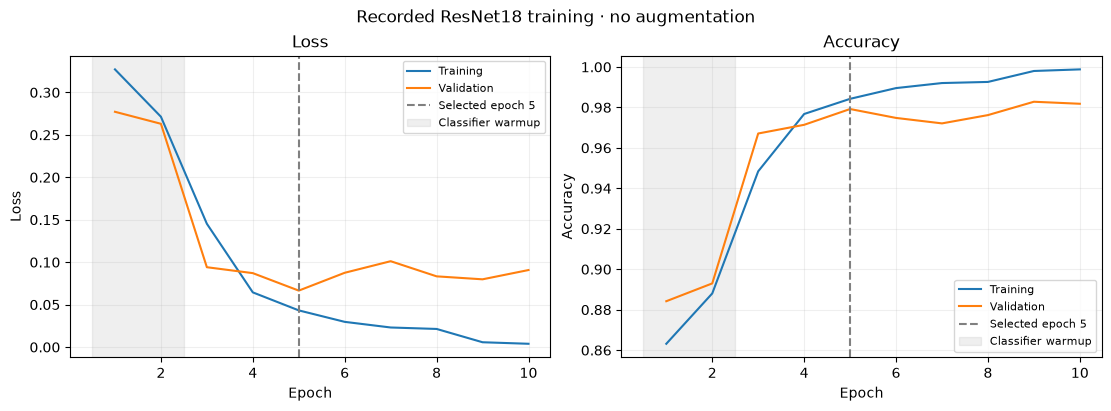

In [22]:
# Plot loss and accuracy separately; they measure different things.
epochs = [int(row["epoch"]) for row in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(epochs, [row[f"train_{metric}"] for row in history], label="Training")
    ax.plot(epochs, [row[f"val_{metric}"] for row in history], label="Validation")
    ax.axvline(selected_epoch, color="grey", ls="--", label=f"Selected epoch {selected_epoch}")
    if MODEL_NAME == "ResNet18":
        ax.axvspan(0.5, 2.5, color="grey", alpha=0.12, label="Classifier warmup")
    ax.set(xlabel="Epoch", ylabel=metric.title(), title=metric.title())
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle(f"Recorded {MODEL_NAME} training · no augmentation")
show_plot()


ResNet18 selected **epoch 5**. Epoch 9 had higher validation accuracy but higher validation loss, so it did not replace epoch 5. The run stopped after epoch 10.


## A2. Clean evaluation

These saved scores document the trained model. They are context for Phase I;
the later image-edit experiments are where we investigate behaviour.
Rows in the confusion matrix are true labels and columns are predictions.


| Split | Images | Accuracy | Fakes detected | Real photos flagged |
| --- | --- | --- | --- | --- |
| validation | 10000 | 97.92% | 98.14% | 2.30% |
| official_test | 20000 | 97.73% | 97.97% | 2.50% |
| unique_test | 19962 | 97.73% | 97.96% | 2.50% |

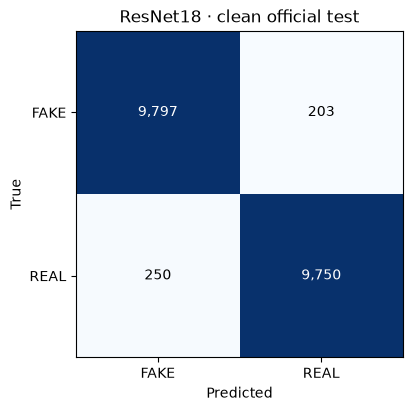

In [23]:
# Read the original evaluation, including the test set with repeated images counted once.
rows = []
for split in ["validation", "official_test", "unique_test"]:
    metrics = report["evaluation"][split]
    rows.append([split, metrics["n"], f"{metrics['accuracy']:.2%}",
                 f"{metrics['fake_detection_rate']:.2%}", f"{metrics['real_flagged_fake_rate']:.2%}"])
show_table(["Split", "Images", "Accuracy", "Fakes detected", "Real photos flagged"], rows)

matrix = np.array(report["evaluation"]["official_test"]["confusion_matrix"])
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ax.imshow(matrix, cmap="Blues")
for row in range(2):
    for column in range(2):
        color = "white" if matrix[row, column] > matrix.max() / 2 else "black"
        ax.text(column, row, f"{matrix[row, column]:,}", ha="center", va="center", color=color)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["FAKE", "REAL"], yticklabels=["FAKE", "REAL"],
       xlabel="Predicted", ylabel="True", title=f"{MODEL_NAME} · clean official test")
show_plot()


## A3. What do the predictions look like?

The bundle includes 600 validation previews, sampled with a fixed seed: 30 per label and
object class. We draw four previews of each label. This small gallery illustrates scores;
the rate curves below use all 10,000 validation images.


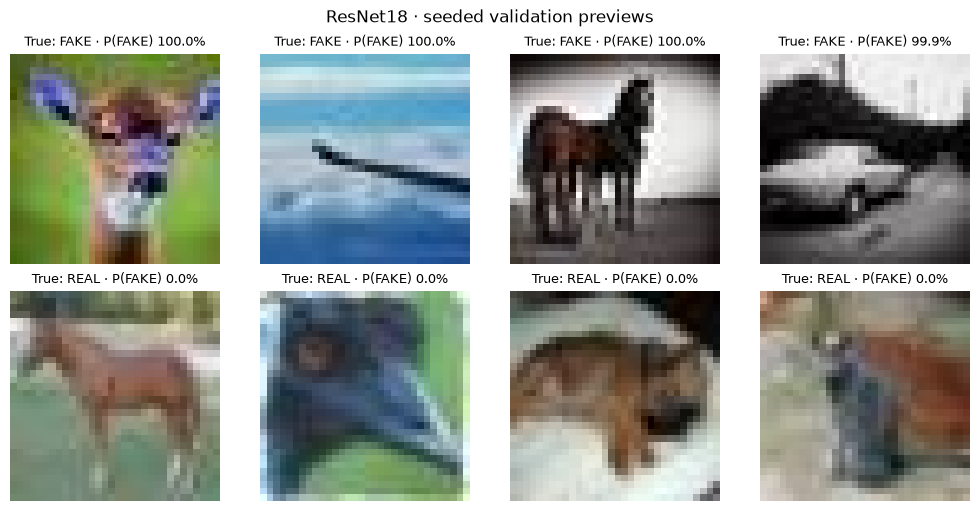

In [24]:
# Image indices point to columns in the saved score arrays.
thumbnails = dict(zip(bundle["thumb_indices"], bundle["thumb_images"]))
preview_indices = bundle["thumb_indices"]
rng = np.random.default_rng(42)
chosen = []
for label in [0, 1]:
    candidates = preview_indices[labels[preview_indices] == label]
    chosen.extend(rng.choice(candidates, 4, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(10, 5), layout="constrained")
for ax, index in zip(axes.flat, chosen):
    truth = "FAKE" if labels[index] == 0 else "REAL"
    ax.imshow(thumbnails[index].transpose(1, 2, 0), interpolation="nearest")
    ax.set_title(f"True: {truth} · P(FAKE) {fake_probability[0, index]:.1%}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{MODEL_NAME} · seeded validation previews")
show_plot()


## A4. Follow one image through each edit

Each row keeps the image fixed while the edit becomes stronger. For each edit, we choose
the preview that was originally correct and moved furthest toward the wrong label at
the second strength. These are selected sensitive examples, not typical cases.
JPEG uses qualities 95/80/60/40; blur 0.3/0.6/1.0/1.5 px; resize 28/24/20/16 px and back;
noise standard deviations 0.01/0.03/0.05/0.10.


In [25]:
# Select examples from the included preview set using an explicit rule.
families = ["JPEG", "Blur", "Resize", "Noise"]
gallery_choices = {}
for label in [0, 1]:
    for family in families:
        second = family_indices(family)[2]
        correct = predicted_fake[0, preview_indices] == (labels[preview_indices] == 0)
        candidates = preview_indices[correct & (labels[preview_indices] == label)]
        change = fake_probability[second, candidates] - fake_probability[0, candidates]
        position = np.argmin(change) if label == 0 else np.argmax(change)
        gallery_choices[(label, family)] = int(candidates[position])


In [26]:
# Draw both labels separately, so missed fakes and false alarms are easy to compare.
def edit_gallery(label):
    fig, axes = plt.subplots(4, 5, figsize=(12, 9), layout="constrained")
    for row, family in enumerate(families):
        index = gallery_choices[(label, family)]
        for column, condition in enumerate(family_indices(family)):
            image = edit_image(thumbnails[index], conditions[condition], index)
            correct = predicted_fake[condition, index] == (label == 0)
            ax = axes[row, column]
            ax.imshow(image.transpose(1, 2, 0), interpolation="nearest")
            score = fake_probability[condition, index]
            ax.set_title(f"{family} · {conditions[condition]['label']}\nP(FAKE) {score:.1%}",
                         fontsize=9, color="seagreen" if correct else "firebrick")
            ax.axis("off")
    truth = "FAKE" if label == 0 else "REAL"
    fig.suptitle(f"{MODEL_NAME} · true label {truth} · selected sensitive previews")
    show_plot()


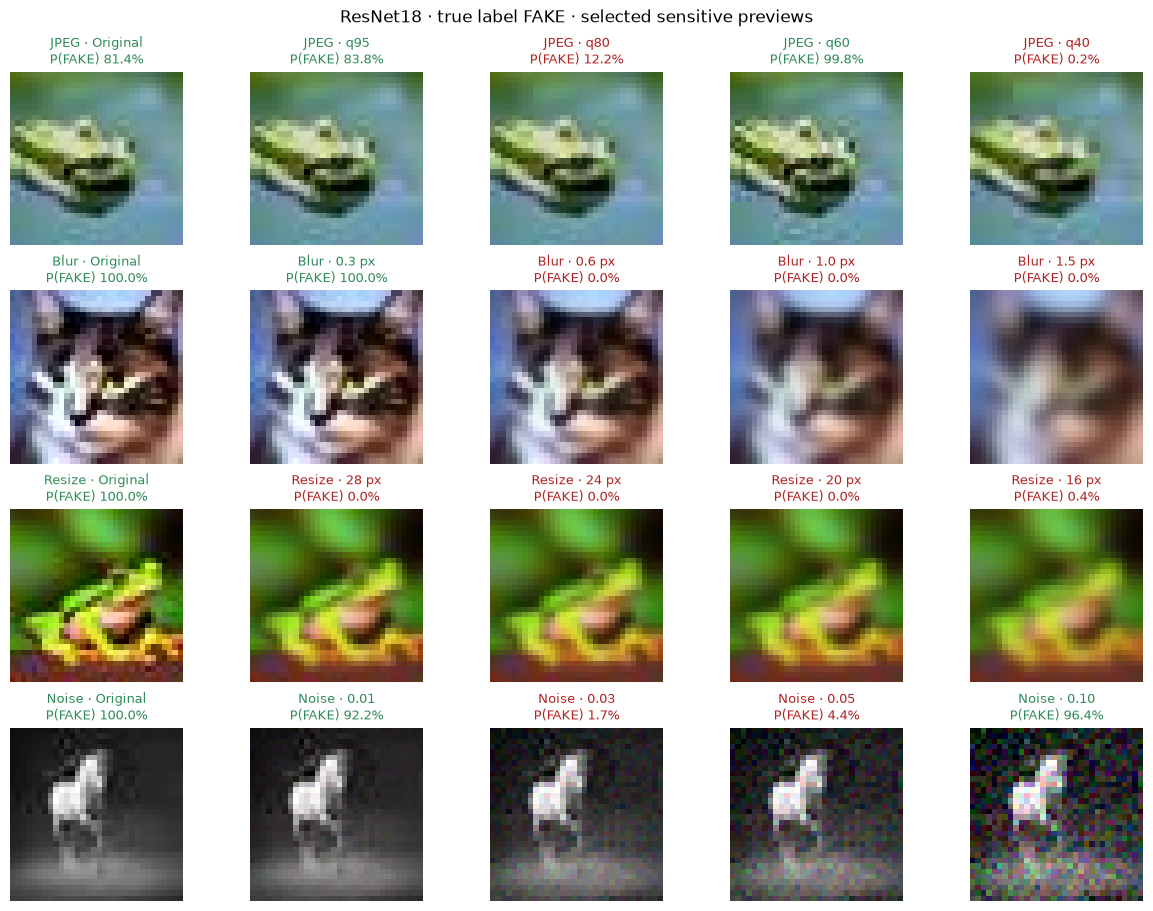

In [27]:
# First follow fakes that become harder to detect.
edit_gallery(0)


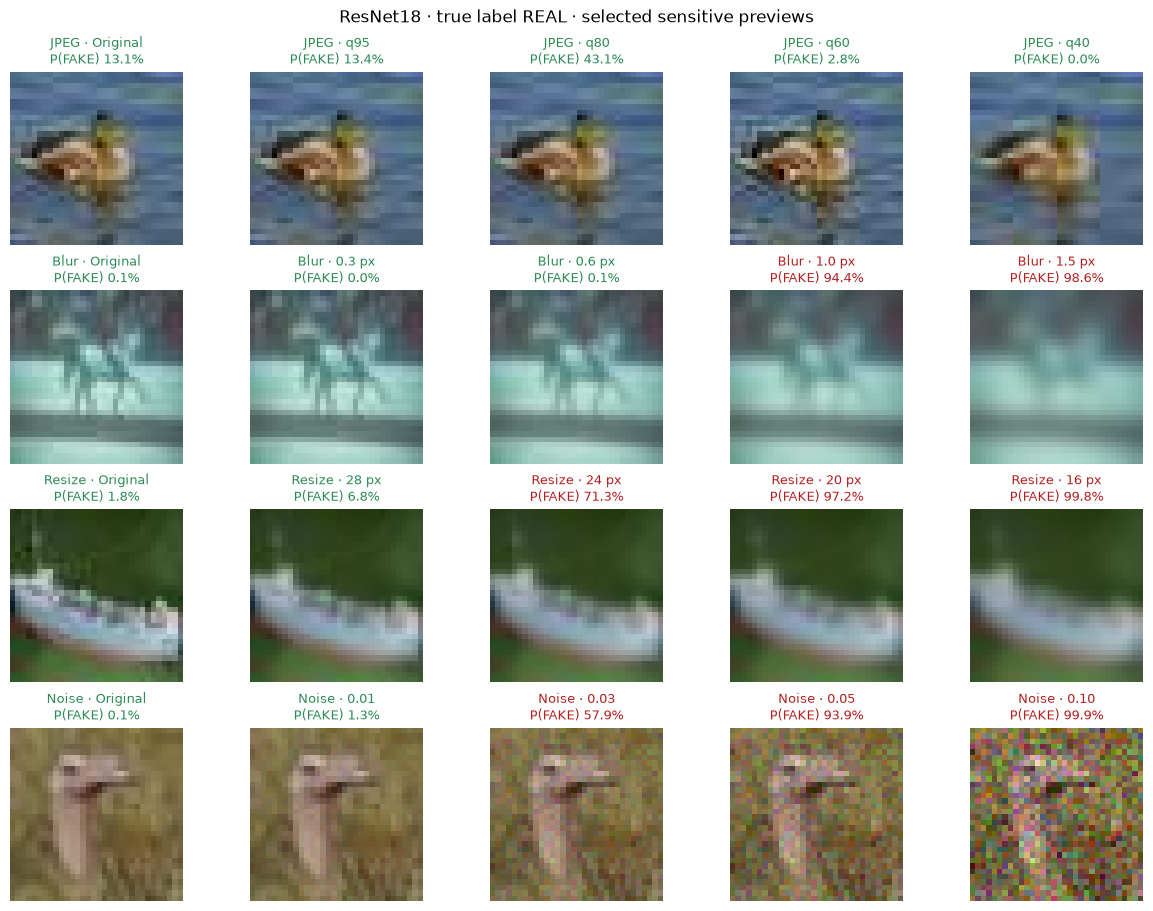

In [28]:
# Then follow real photos that receive higher FAKE scores.
edit_gallery(1)


## A5. How common is that behaviour?

These curves use all 10,000 validation images. The false-alarm curve is especially useful:
a model that calls almost everything REAL can accept real photos while missing most fakes.
Strengths in different panels do not represent equal visual changes.


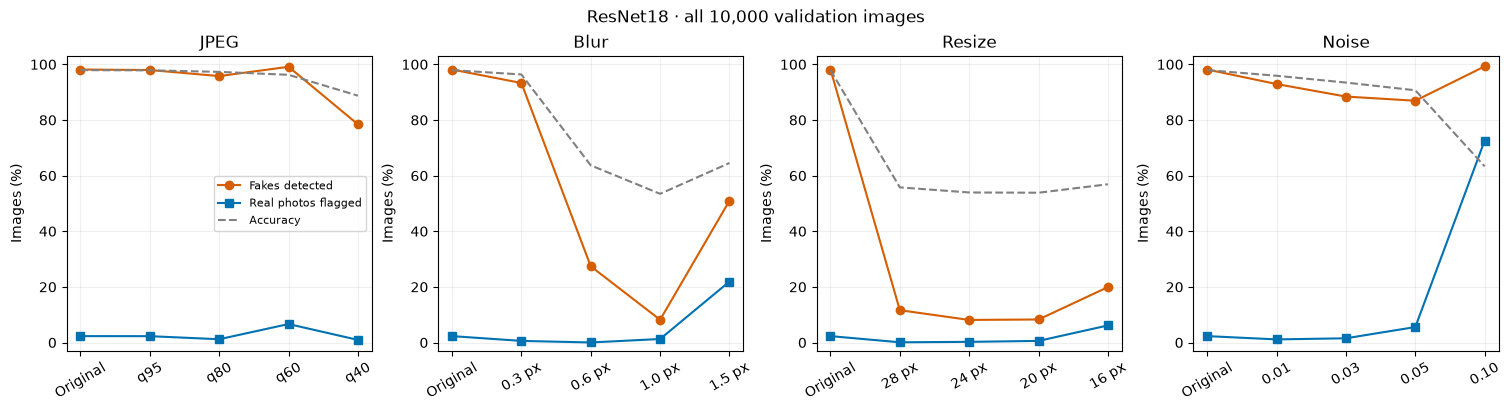

In [29]:
# Keep the same rate definitions for all four edit families.
fig, axes = plt.subplots(1, 4, figsize=(15, 4), layout="constrained")
for ax, family in zip(axes, families):
    indices = family_indices(family)
    ax.plot(range(5), 100*rates["Fakes detected"][indices], "o-", color=FAKE_COLOR, label="Fakes detected")
    ax.plot(range(5), 100*rates["Real photos flagged"][indices], "s-", color=REAL_COLOR, label="Real photos flagged")
    ax.plot(range(5), 100*rates["Accuracy"][indices], "--", color="grey", label="Accuracy")
    ax.set(xticks=range(5), xticklabels=[conditions[i]["label"] for i in indices],
           ylim=(-3, 103), ylabel="Images (%)", title=family)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig.suptitle(f"{MODEL_NAME} · all 10,000 validation images")
show_plot()


## A6. How far do the scores move?

The diagonal means no change. Below it, an image moved toward REAL; above it, toward FAKE.
We use the same seeded 400 REAL and 400 FAKE images in every panel, at the second edit strength.


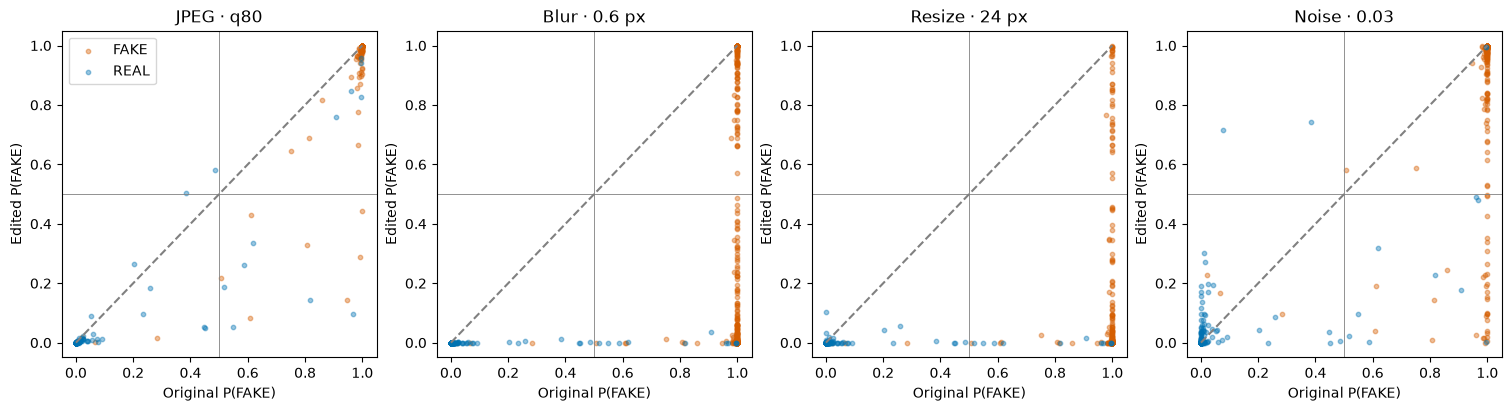

In [30]:
# A balanced sample keeps the scatter readable without changing it between edits.
rng = np.random.default_rng(2026)
sample = np.concatenate([rng.choice(np.flatnonzero(labels == label), 400, replace=False) for label in [0, 1]])
fig, axes = plt.subplots(1, 4, figsize=(15, 4), layout="constrained")
for ax, family in zip(axes, families):
    condition = family_indices(family)[2]
    for label, color, name in [(0, FAKE_COLOR, "FAKE"), (1, REAL_COLOR, "REAL")]:
        indices = sample[labels[sample] == label]
        ax.scatter(fake_probability[0, indices], fake_probability[condition, indices], s=10, alpha=0.4, c=color, label=name)
    ax.plot([0, 1], [0, 1], color="grey", ls="--")
    ax.axhline(0.5, color="grey", lw=0.6)
    ax.axvline(0.5, color="grey", lw=0.6)
    ax.set(xlabel="Original P(FAKE)", ylabel="Edited P(FAKE)", title=f"{family} · {conditions[condition]['label']}")
axes[0].legend()
show_plot()


# Part B · AI-assisted visualizations

These follow-up analyses were developed with AI assistance. They investigate the image
properties behind the rate changes using sharpening, colour edits, conditional curves
and image groups. The models remain fixed throughout.

## B1. Do clean errors follow sharpness?

The data notebook found that fakes tend to be sharper. We divide all validation images
into ten sharpness groups, then count missed fakes and false alarms within each group.
The intervals and group counts help us avoid overreading a small subgroup.


In [31]:
# These descriptors were calculated from pixels, not from model activations.
descriptor_names = list(bundle["descriptor_names"])
image_stats = bundle["descriptors"].astype(np.float32)
sharpness_column = descriptor_names.index("log_sharpness")
saturation_column = descriptor_names.index("saturation")
original_sharpness = image_stats[0, :, sharpness_column]
saturation = image_stats[0, :, saturation_column]
blur_index = condition_index("Blur", 0.6)
resize_index = condition_index("Resize", 28)
object_names = list(bundle["object_names"])

# Use one pooled set of decile boundaries for both labels.
edges = np.quantile(original_sharpness, np.linspace(0, 1, 11))
decile = np.clip(np.searchsorted(edges, original_sharpness, side="right") - 1, 0, 9)


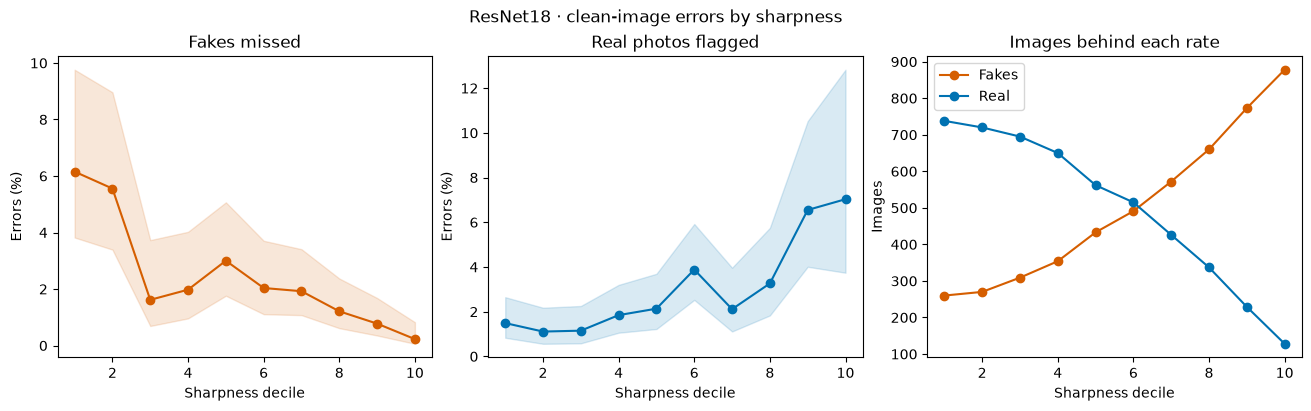

In [32]:
# Wilson intervals describe uncertainty in a binomial error rate.
def wilson(errors, count):
    proportion = errors / count
    z = 1.96
    denominator = 1 + z*z/count
    centre = (proportion + z*z/(2*count)) / denominator
    half = z*np.sqrt(proportion*(1-proportion)/count + z*z/(4*count*count)) / denominator
    return centre - half, centre + half

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, mask, wrong, color, title in [
    (axes[0], fake_mask, ~predicted_fake[0], FAKE_COLOR, "Fakes missed"),
    (axes[1], real_mask, predicted_fake[0], REAL_COLOR, "Real photos flagged"),
]:
    counts = np.array([(mask & (decile == group)).sum() for group in range(10)])
    errors = np.array([wrong[mask & (decile == group)].sum() for group in range(10)])
    lower, upper = np.array([wilson(k, n) for k, n in zip(errors, counts)]).T
    ax.plot(range(1, 11), 100*errors/counts, "o-", color=color)
    ax.fill_between(range(1, 11), 100*lower, 100*upper, color=color, alpha=0.15)
    ax.set(xlabel="Sharpness decile", ylabel="Errors (%)", title=title)
    axes[2].plot(range(1, 11), counts, "o-", color=color, label=title.split()[0])
axes[2].set(xlabel="Sharpness decile", ylabel="Images", title="Images behind each rate")
axes[2].legend()
fig.suptitle(f"{MODEL_NAME} · clean-image errors by sharpness")
show_plot()


In [33]:
# Sharpness alone is not enough if the model still separates labels within each decile.
auc_by_decile = [roc_auc_score(labels[decile == group], logits[0, decile == group]) for group in range(10)]
print(f"Sharpness alone: AUC {roc_auc_score(fake_mask, original_sharpness):.3f}")
print(f"Model AUC within sharpness deciles: {min(auc_by_decile):.3f}–{max(auc_by_decile):.3f}")


Sharpness alone: AUC 0.732
Model AUC within sharpness deciles: 0.994–0.999


## B2. Adding detail as well as removing it

Each line follows an edit family. The horizontal axis is the median sharpness of edited
images, and the vertical axis is the share predicted FAKE. Sharpening tests the opposite
direction from blur. Blur followed by sharpening tests whether the output can move back.


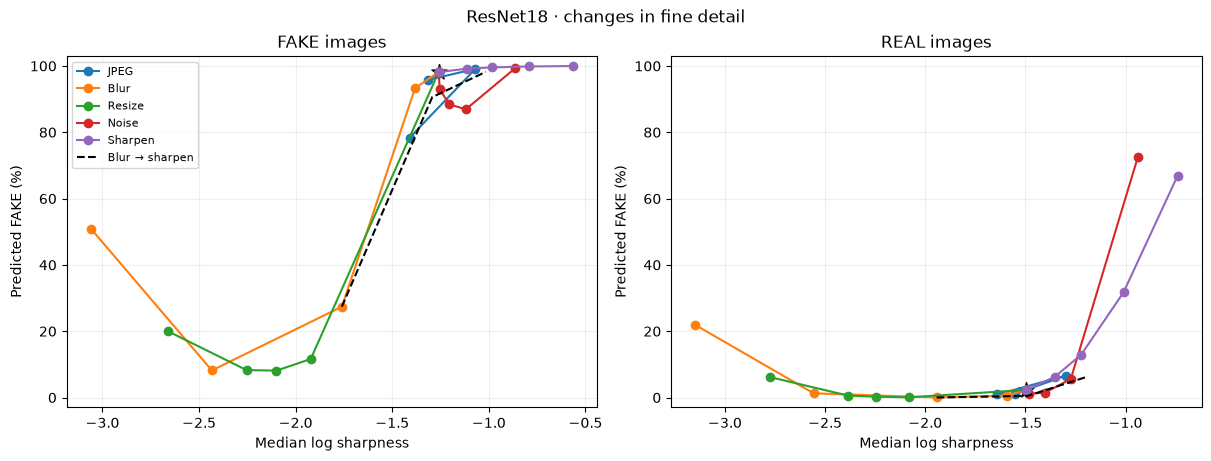

In [34]:
# Plot REAL and FAKE separately: the same upward movement has different consequences.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, mask, name in [(axes[0], fake_mask, "FAKE"), (axes[1], real_mask, "REAL")]:
    for family in families + ["Sharpen"]:
        indices = family_indices(family)
        sharpness = np.median(image_stats[indices][:, mask, sharpness_column], axis=1)
        rate = predicted_fake[indices][:, mask].mean(axis=1)
        ax.plot(sharpness, 100*rate, "o-", label=family)
    # Connect blur to the two sharpening-after-blur conditions.
    indices = [blur_index, condition_index("Blur→Sharpen", 100), condition_index("Blur→Sharpen", 200)]
    ax.plot(np.median(image_stats[indices][:, mask, sharpness_column], axis=1),
            100*predicted_fake[indices][:, mask].mean(axis=1), "k--", label="Blur → sharpen")
    ax.scatter(np.median(original_sharpness[mask]), 100*predicted_fake[0, mask].mean(), c="black", marker="*", s=130)
    ax.set(xlabel="Median log sharpness", ylabel="Predicted FAKE (%)", title=f"{name} images", ylim=(-3, 103))
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig.suptitle(f"{MODEL_NAME} · changes in fine detail")
show_plot()


In [35]:
# Print the main counterfactual measurements directly from the saved predictions.
sharpen_index = condition_index("Sharpen", 200)
restore_index = condition_index("Blur→Sharpen", 100)
print(f"Real photos flagged: original {predicted_fake[0, real_mask].mean():.1%}; sharpened {predicted_fake[sharpen_index, real_mask].mean():.1%}")
print(f"Fakes detected: blurred {predicted_fake[blur_index, fake_mask].mean():.1%}; blur then sharpen {predicted_fake[restore_index, fake_mask].mean():.1%}")


Real photos flagged: original 2.3%; sharpened 66.9%
Fakes detected: blurred 27.4%; blur then sharpen 90.6%


Fine detail strongly changes the decisions, but it is not the entire explanation.
Noise adds high-frequency energy while sometimes reducing fake detection, unlike sharpening.
The strongest blur and resize settings also leave the common trend. These tests change
more than one image property, so they do not isolate a single internal mechanism.


## B3. A confidence shift or lost separation?

Boxes show the middle half of REAL logits and whiskers the 5th–95th percentiles.
The dotted line is the fixed decision threshold. The AUC above each setting measures
ranking, regardless of that threshold.


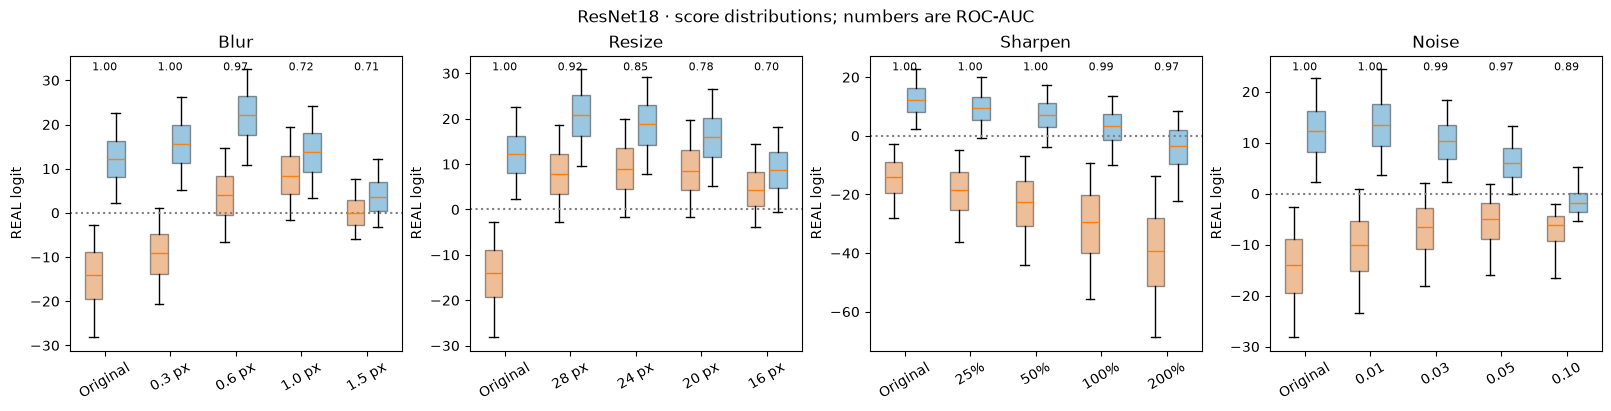

In [36]:
# AUC can stay high even when most fake scores cross the zero threshold.
fig, axes = plt.subplots(1, 4, figsize=(16, 4), layout="constrained")
for ax, family in zip(axes, ["Blur", "Resize", "Sharpen", "Noise"]):
    indices = family_indices(family)
    for offset, mask, color in [(-0.17, fake_mask, FAKE_COLOR), (0.17, real_mask, REAL_COLOR)]:
        values = [logits[index, mask] for index in indices]
        boxes = ax.boxplot(values, positions=np.arange(5)+offset, widths=0.27,
                           whis=(5, 95), showfliers=False, patch_artist=True, manage_ticks=False)
        for box in boxes["boxes"]:
            box.set(facecolor=color, alpha=0.4)
    for position, index in enumerate(indices):
        auc = roc_auc_score(labels, logits[index])
        ax.text(position, 0.98, f"{auc:.2f}", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)
    ax.axhline(0, color="grey", ls=":")
    ax.set(xticks=range(5), xticklabels=[conditions[i]["label"] for i in indices], title=family, ylabel="REAL logit")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"{MODEL_NAME} · score distributions; numbers are ROC-AUC")
show_plot()


In [37]:
# Compare ranking and threshold-based accuracy for the same resized images.
print(f"Resize 28 px: accuracy {rates['Accuracy'][resize_index]:.2%}; AUC {roc_auc_score(labels, logits[resize_index]):.3f}")


Resize 28 px: accuracy 55.77%; AUC 0.916


## B4. Does every image react equally?

Each thin line follows one image, centred at its original logit. The thick line averages
all 5,000 images of that label. Colour shows original sharpness. These are centred ICE
curves over edit strength, rather than independent changes to a tabular feature.


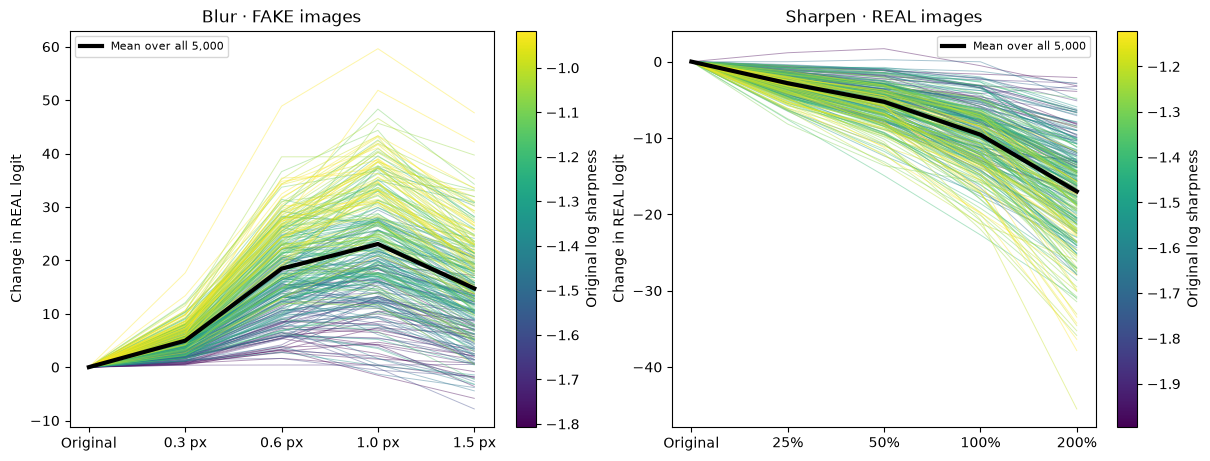

In [38]:
# Subtract each image's own starting score before comparing reactions.
rng = np.random.default_rng(2026)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, family, mask in [(axes[0], "Blur", fake_mask), (axes[1], "Sharpen", real_mask)]:
    sample = rng.choice(np.flatnonzero(mask), 300, replace=False)
    indices = family_indices(family)
    changes = logits[indices] - logits[0]
    lower, upper = np.percentile(original_sharpness[mask], [5, 95])
    norm = plt.Normalize(lower, upper)
    for index in sample[np.argsort(original_sharpness[sample])]:
        ax.plot(range(5), changes[:, index], color=plt.cm.viridis(norm(original_sharpness[index])), alpha=0.4, lw=0.7)
    ax.plot(range(5), changes[:, mask].mean(axis=1), color="black", lw=3, label="Mean over all 5,000")
    ax.set(xticks=range(5), xticklabels=[conditions[i]["label"] for i in indices],
           ylabel="Change in REAL logit", title=f"{family} · {'FAKE' if family == 'Blur' else 'REAL'} images")
    ax.legend(fontsize=8)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax, label="Original log sharpness")
show_plot()


In [39]:
# Use all fakes for the correlation, not just the 300 lines shown above.
blur_change = logits[blur_index] - logits[0]
correlation = spearmanr(original_sharpness[fake_mask], blur_change[fake_mask]).statistic
print(f"Original sharpness versus blur-induced logit change: Spearman rho = {correlation:.2f}")


Original sharpness versus blur-induced logit change: Spearman rho = 0.70


## B5. Which object classes keep being detected after blur?

We follow fake images through blur, then blur with saturation reduced to 75% and 50%.
This tests whether colour provides another cue after fine detail is weakened. A saturation
multiplier of 0.5 reduces colour; it does not remove all colour.


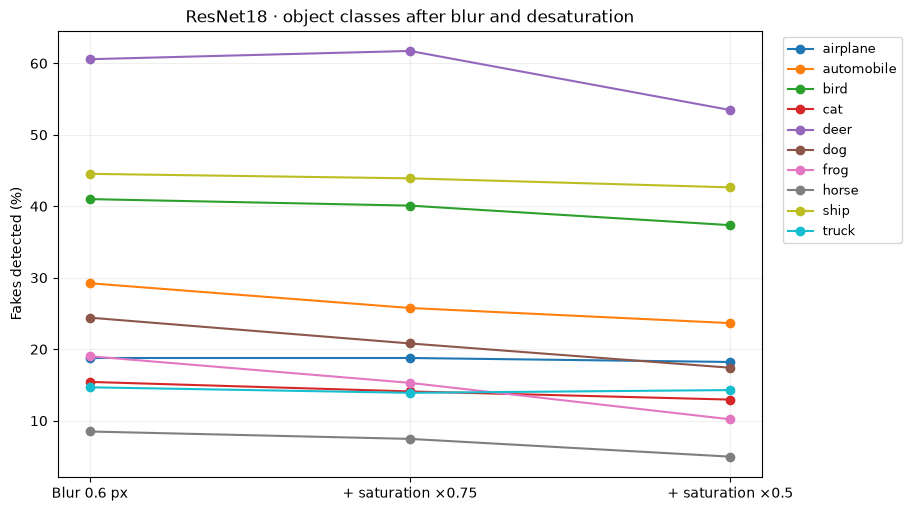

In [40]:
# Calculate each class's rates before drawing the lines.
chain = [blur_index, condition_index("Blur→Desaturate", 0.75), condition_index("Blur→Desaturate", 0.5)]
class_rates = np.zeros((10, 3))
class_saturation = np.zeros(10)
for object_id in range(10):
    mask = fake_mask & (objects == object_id)
    class_rates[object_id] = predicted_fake[chain][:, mask].mean(axis=1)
    class_saturation[object_id] = np.median(saturation[mask])
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for object_id, name in enumerate(object_names):
    ax.plot(range(3), 100*class_rates[object_id], "o-", label=name)
ax.set(xticks=range(3), xticklabels=["Blur 0.6 px", "+ saturation ×0.75", "+ saturation ×0.5"],
       ylabel="Fakes detected (%)", title=f"{MODEL_NAME} · object classes after blur and desaturation")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax.grid(alpha=0.2)
show_plot()


In [41]:
# Check the class association and the colour-only control.
drop = class_rates[:, 0] - class_rates[:, -1]
print(f"Class saturation versus detection drop: rho = {spearmanr(class_saturation, drop).statistic:.2f}")
colour_only = [i for i, item in enumerate(conditions) if item["family"] == "Saturation"]
colour_rates = predicted_fake[colour_only][:, fake_mask].mean(axis=1)
print(f"Detection with colour-only edits: {colour_rates.min():.1%}–{colour_rates.max():.1%}")


Class saturation versus detection drop: rho = 0.56
Detection with colour-only edits: 97.0%–98.2%


The colour-only control changes detection much less than blur followed by desaturation.
That supports colour as a secondary cue in this experiment, particularly for the CNN.
Class-level correlations describe ten groups; they are not proof of a particular internal pathway.


## B6. Do the same images change their prediction?

Each column is one validation image. We take 100 FAKE and 100 REAL images with a fixed
seed, then order each label by its original score. Grey means the prediction stayed the
same, orange means a new mistake, and blue means an original mistake was corrected.


In [42]:
# The fixed sample lets us follow individual images across the four original edits.
from matplotlib.colors import ListedColormap
rng = np.random.default_rng(42)
sample = []
for mask in [fake_mask, real_mask]:
    chosen = rng.choice(np.flatnonzero(mask), 100, replace=False)
    sample.extend(chosen[np.argsort(fake_probability[0, chosen])])
sample = np.array(sample)
edit_indices = [i for i, item in enumerate(conditions) if item["family"] in ["JPEG", "Blur", "Resize", "Noise"]]
correct = predicted_fake[:, sample] == fake_mask[sample]
changes = np.zeros((len(edit_indices), len(sample)), dtype=int)
changes[correct[0] & ~correct[edit_indices]] = 1
changes[~correct[0] & correct[edit_indices]] = 2


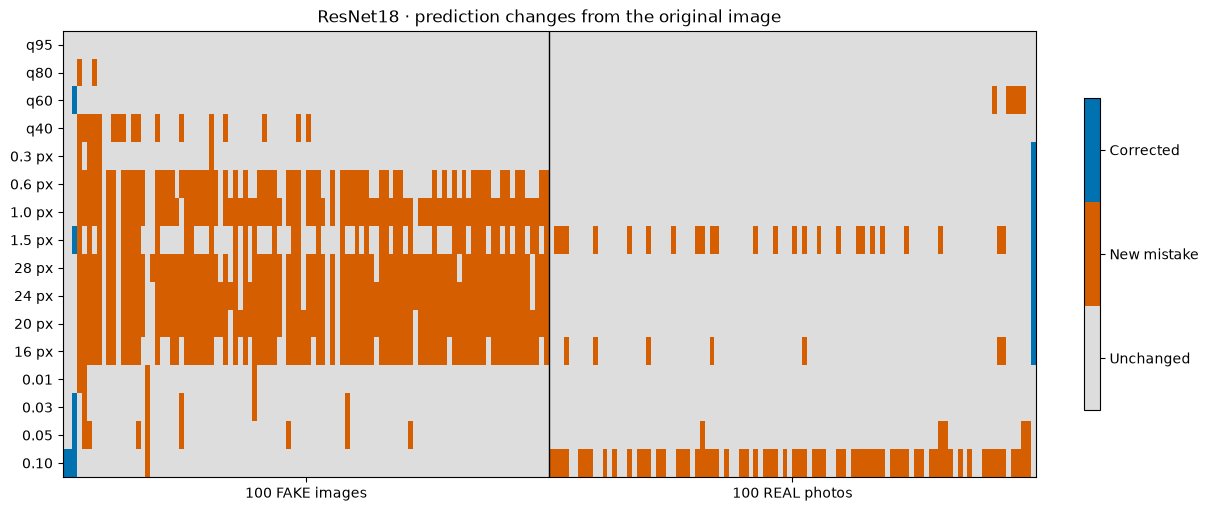

In [43]:
# A column with several orange cells is an image that fails under several edits.
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
heat = ax.imshow(changes, aspect="auto", cmap=ListedColormap(["#dddddd", FAKE_COLOR, REAL_COLOR]), vmin=-0.5, vmax=2.5)
ax.axvline(99.5, color="black", lw=1)
ax.set(yticks=range(len(edit_indices)), yticklabels=[conditions[i]["label"] for i in edit_indices],
       xticks=[49.5, 149.5], xticklabels=["100 FAKE images", "100 REAL photos"],
       title=f"{MODEL_NAME} · prediction changes from the original image")
bar = fig.colorbar(heat, ax=ax, ticks=[0, 1, 2], shrink=0.7)
bar.ax.set_yticklabels(["Unchanged", "New mistake", "Corrected"])
show_plot()


## B7. Compare the two models on the same images

Here we bring the CNN back into the picture. The coordinates come from image
measurements only, not hidden layers. We use all 5,000 fake validation images and
colour the map afterwards by whether each detector still detects them after blur.

Two t-SNE settings and a PCA view help us check whether a pattern depends on one layout.
A gap in t-SNE does not prove that separate natural groups exist. The six groups below
come from k-means on the original standardized measurements, not from the map.


In [44]:
# Six image properties plus eight frequency bands describe each fake image.
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
fake_index = np.flatnonzero(fake_mask)
descriptor_names = list(bundle["descriptor_names"])
feature_names = descriptor_names + [f"band {i+1}" for i in range(8)]
features = np.column_stack([image_stats[0, fake_index],
                            np.log10(bundle["bands_original"][fake_index].astype(float) + 1e-6)])
standardized = (features - features.mean(axis=0)) / features.std(axis=0)
cnn_fake = bundle["cnn_logit"] < 0
resnet_fake = bundle["resnet_logit"] < 0
cnn_survives = cnn_fake[blur_index, fake_index]
resnet_survives = resnet_fake[blur_index, fake_index]
both_survive = cnn_survives & resnet_survives
# 0: neither detects it; 1: CNN only; 2: ResNet only; 3: both.
outcomes = cnn_survives.astype(int) + 2 * resnet_survives.astype(int)


In [45]:
# Number groups by the share detected by both models, from highest to lowest.
raw_groups = KMeans(n_clusters=6, n_init=20, random_state=0).fit_predict(standardized)
ranked = sorted(range(6), key=lambda group: both_survive[raw_groups == group].mean(), reverse=True)
groups = np.array([ranked.index(group) for group in raw_groups])
maps = {
    "t-SNE · perplexity 30": TSNE(perplexity=30, init="pca", learning_rate="auto", random_state=0).fit_transform(standardized),
    "t-SNE · perplexity 100": TSNE(perplexity=100, init="pca", learning_rate="auto", random_state=0).fit_transform(standardized),
    "PCA": PCA(n_components=2).fit_transform(standardized),
}


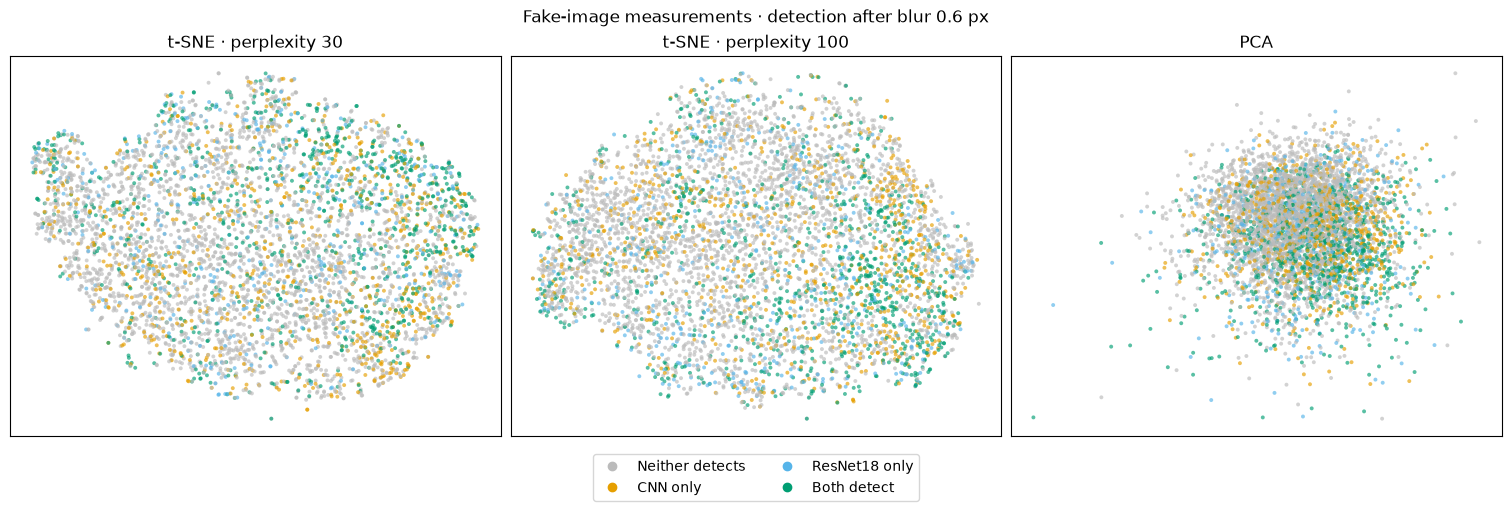

In [46]:
# Mix the drawing order so one outcome does not cover all the others.
outcome_names = ["Neither detects", "CNN only", "ResNet18 only", "Both detect"]
outcome_colors = ["#bbbbbb", "#E69F00", "#56B4E9", "#009E73"]
order = np.random.default_rng(0).permutation(len(fake_index))
fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
for ax, (title, coordinates) in zip(axes, maps.items()):
    ax.scatter(*coordinates[order].T, c=np.array(outcome_colors)[outcomes[order]], s=8, alpha=0.65, linewidths=0)
    ax.set(title=title, xticks=[], yticks=[])
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", color=color, label=name)
           for name, color in zip(outcome_names, outcome_colors)]
axes[1].legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.03), ncol=2)
fig.suptitle("Fake-image measurements · detection after blur 0.6 px")
show_plot()


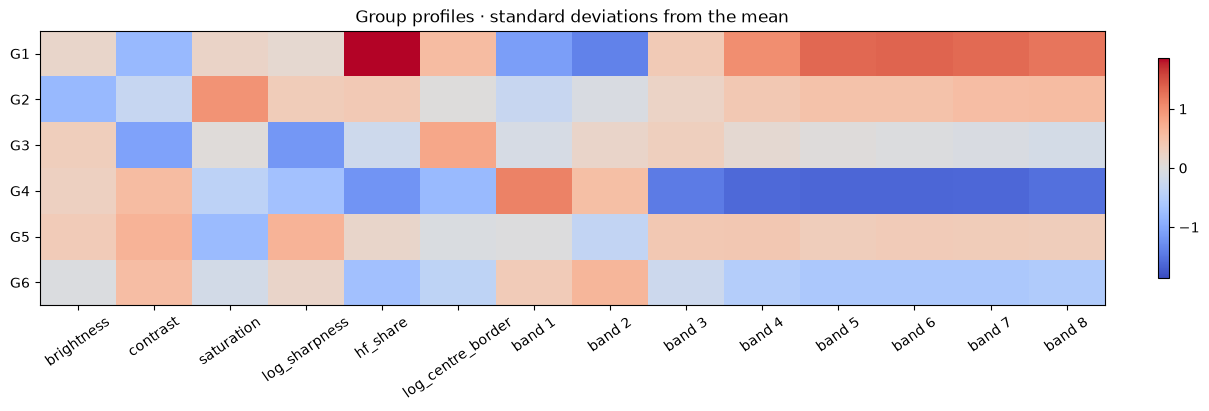

In [47]:
# A profile says how each group's average differs from the average fake image.
profiles = np.array([standardized[groups == group].mean(axis=0) for group in range(6)])
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
limit = abs(profiles).max()
heat = ax.imshow(profiles, cmap="coolwarm", vmin=-limit, vmax=limit, aspect="auto")
ax.set(xticks=range(len(feature_names)), xticklabels=feature_names,
       yticks=range(6), yticklabels=[f"G{i+1}" for i in range(6)], title="Group profiles · standard deviations from the mean")
ax.tick_params(axis="x", rotation=35)
fig.colorbar(heat, ax=ax, shrink=0.8)
show_plot()


In [48]:
# Object classes describe the groups afterwards; they were not used to make them.
rows = []
for group in range(6):
    mask = groups == group
    common = np.argsort(np.bincount(objects[fake_index[mask]], minlength=10))[-2:][::-1]
    rows.append([f"G{group+1}", mask.sum(), f"{cnn_survives[mask].mean():.1%}",
                 f"{resnet_survives[mask].mean():.1%}", f"{both_survive[mask].mean():.1%}",
                 ", ".join(object_names[i] for i in common)])
show_table(["Group", "Images", "CNN detects", "ResNet18 detects", "Both detect", "Common classes"], rows)


| Group | Images | CNN detects | ResNet18 detects | Both detect | Common classes |
| --- | --- | --- | --- | --- | --- |
| G1 | 627 | 52.5% | 39.7% | 29.2% | airplane, deer |
| G2 | 938 | 46.6% | 32.4% | 24.5% | frog, deer |
| G3 | 740 | 36.8% | 34.9% | 21.4% | bird, airplane |
| G4 | 510 | 30.4% | 25.9% | 16.5% | ship, truck |
| G5 | 887 | 22.0% | 22.0% | 11.3% | cat, truck |
| G6 | 1298 | 23.2% | 17.9% | 9.5% | horse, automobile |

Groups with a lot of relative high-frequency detail survive blur more often. Another
robust group contains saturated frog and deer images. This gives us more specific examples
to investigate than a single overall accuracy, but six is an exploratory choice of group count.


## B8. Do they make the same mistakes?

The scatter compares scores for the same fake images after resizing to 28 pixels.
The overlap plot compares observed shared errors with the overlap expected if the two
models' errors were independent. Jaccard overlap is shared errors divided by errors in either model.


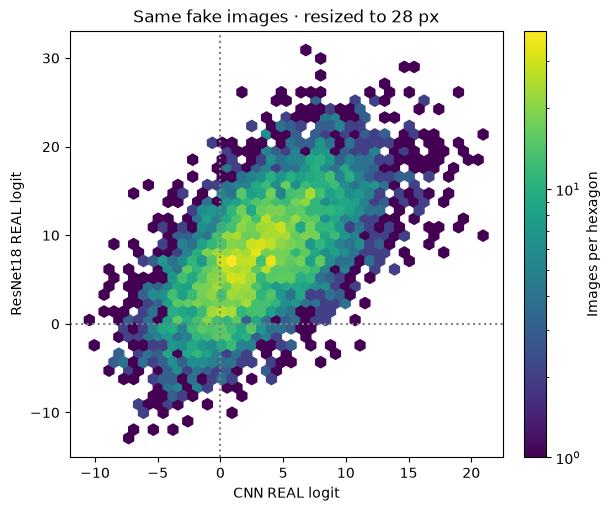

In [49]:
# A log-density plot keeps all 5,000 resized fakes visible without overplotting.
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
density = ax.hexbin(bundle["cnn_logit"][resize_index, fake_mask], logits[resize_index, fake_mask],
                    gridsize=40, mincnt=1, bins="log", cmap="viridis")
ax.axhline(0, color="grey", ls=":")
ax.axvline(0, color="grey", ls=":")
ax.set(xlabel="CNN REAL logit", ylabel="ResNet18 REAL logit", title="Same fake images · resized to 28 px")
fig.colorbar(density, ax=ax, label="Images per hexagon")
show_plot()


In [50]:
# Use the actual error rates for the independence baseline.
checks = [0, condition_index("JPEG", 60), blur_index, resize_index, condition_index("Noise", 0.1)]
overlap_rows, overlap_labels = [], []
for index in checks:
    for mask, name in [(fake_mask, "FAKE"), (real_mask, "REAL")]:
        cnn_wrong = cnn_fake[index, mask] != fake_mask[mask]
        resnet_wrong = resnet_fake[index, mask] != fake_mask[mask]
        union = (cnn_wrong | resnet_wrong).sum()
        observed = (cnn_wrong & resnet_wrong).sum() / union if union else 0
        p, q = cnn_wrong.mean(), resnet_wrong.mean()
        expected = p * q / (p + q - p * q) if p + q else 0
        overlap_rows.append([observed, expected])
        overlap_labels.append(f"{conditions[index]['label']} · {name}")


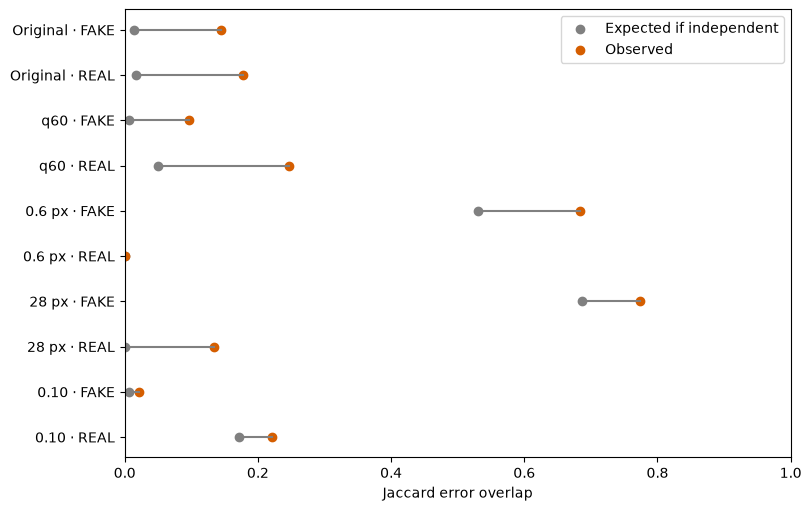

In [51]:
# Connect each pair to show how far the shared errors exceed independence.
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
for row, (observed, expected) in enumerate(overlap_rows):
    ax.plot([expected, observed], [row, row], color="grey")
values = np.array(overlap_rows)
ax.scatter(values[:, 1], range(len(values)), label="Expected if independent", color="grey")
ax.scatter(values[:, 0], range(len(values)), label="Observed", color=FAKE_COLOR)
ax.set(yticks=range(len(values)), yticklabels=overlap_labels, xlabel="Jaccard error overlap", xlim=(0, 1))
ax.invert_yaxis()
ax.legend()
show_plot()


## What we learned

ResNet18 detects 98.1% of clean fakes, but only 27.4% after blur 0.6 px and
11.6% after resizing to 28 px. Its stronger clean result does not protect it from these
edits. CNN and ResNet errors often affect the same images, although noise produces
a much larger real-photo false-alarm rate for ResNet18.

These findings describe one selected run per model on CIFAKE's small 32×32 images.
The behaviour tests use the same 10,000 validation images and fixed threshold throughout.
Several edits affect more than one image property, so the plots suggest explanations
rather than proving which internal feature a model uses. Phase II investigates those features.
